# Volume 0, Chapter 5: Sequences, Series and Limits (Python companion)

Exercises first, solutions at the end. Computer-science threads: **floating-point summation** (why the order of a sum
matters on a computer too) and **convergence acceleration** (getting 20 digits from a series that converges like $1/n$).

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
import mpmath as mp

## Exercises

**P5.1 (★) Watch the limits.** Check numerically that $u_n\sqrt{n/3} \to 1$ for $u_{n+1} = \sin u_n$ (Exercise 5.4), and that $n!/(\sqrt{2\pi n}(n/e)^n) \to 1$ (Stirling). Plot both.

In [2]:
# Your code here


**P5.2 (★★) Riemann's rearrangement, live.** Write a greedy rearrangement of $\sum (-1)^{n+1}/n$ that reaches any target $x$: add unused positive terms while the sum is below $x$, unused negative terms while it is above. Plot the partial sums for $x = \pi$. Then check Exercise 5.6 with $p = 3$, $q = 1$.

In [3]:
# Your code here


**P5.3 (★★) CS application: floating-point summation.** In float64, compute $H_n$ for $n = 10^7$ summing forwards ($1 + \frac12 + \cdots$) and backwards ($\frac1n + \cdots + 1$), and compare with the exact value from `mpmath`. Then implement **Kahan's compensated summation** and compare again. Which order is better, and why?

In [4]:
# Your code here


**P5.4 (★★) CS application: computing $\gamma$.** Approximating $\gamma$ by $H_n - \ln n$ gains about one digit per tenfold increase of $n$. Use the Euler–Maclaurin correction $\gamma \approx H_n - \ln n - \frac1{2n} + \frac1{12n^2} - \frac1{120n^4}$ instead, in `mpmath` at 30 digits, and compare with `mp.euler`. How many correct digits do you get with $n = 1000$?

In [5]:
# Your code here


**P5.5 (★★★) Kempner, honestly.** Summing $1/n$ over the integers without digit 9 converges very slowly. Compute the partial sums up to $N = 10^k$ for $k \le 7$, look at how the increments shrink from one decade to the next, and estimate how many digits $N$ would need for the partial sum to get within $0.01$ of the true value $22.92$.

In [6]:
# Your code here


---
## Solutions

### P5.1

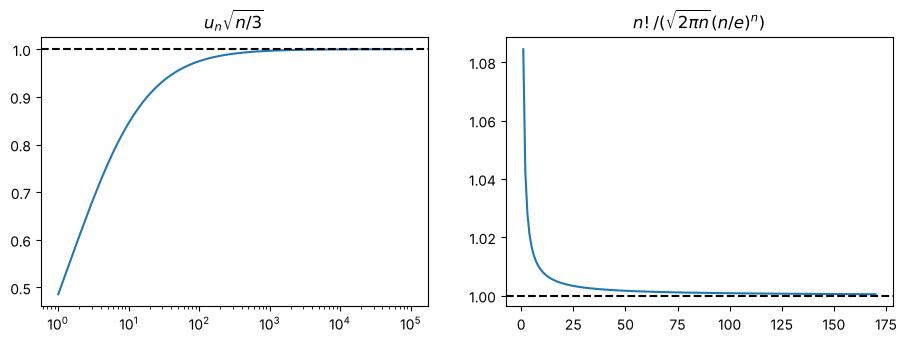

0.9999533119478982 1.0004903156784803  (Stirling ratio is about 1 + 1/(12n))


In [7]:
N = 10**5
u, ratios = 1.0, []
for n in range(1, N + 1):
    u = math.sin(u)
    ratios.append(u * math.sqrt(n / 3))
ns = np.arange(1, 171)
stirling = [math.factorial(n) / (math.sqrt(2 * math.pi * n) * (n / math.e) ** n) for n in ns]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].semilogx(np.arange(1, N + 1), ratios); ax[0].axhline(1, ls="--", c="k"); ax[0].set_title(r"$u_n\sqrt{n/3}$")
ax[1].plot(ns, stirling); ax[1].axhline(1, ls="--", c="k"); ax[1].set_title(r"$n!/(\sqrt{2\pi n}(n/e)^n)$")
plt.show()
print(ratios[-1], stirling[-1], " (Stirling ratio is about 1 + 1/(12n))")

### P5.2

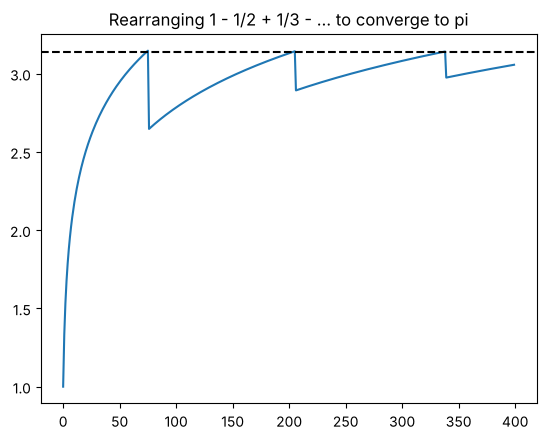

after 20000 terms: 3.140883775126623


p=3, q=1: 1.2424530748936644  predicted: 1.2424533248940002


In [8]:
def greedy_rearrangement(target, steps):
    pos, neg, s, sums = 1, 2, 0.0, []
    for _ in range(steps):
        if s <= target:
            s += 1 / pos; pos += 2
        else:
            s -= 1 / neg; neg += 2
        sums.append(s)
    return sums

sums = greedy_rearrangement(math.pi, 20_000)
plt.plot(sums[:400]); plt.axhline(math.pi, ls="--", c="k"); plt.title("Rearranging 1 - 1/2 + 1/3 - ... to converge to pi"); plt.show()
print("after 20000 terms:", sums[-1])

def block_sum(p, q, blocks):
    odd, even, s = 1, 2, 0.0
    for _ in range(blocks):
        for _ in range(p):
            s += 1 / odd; odd += 2
        for _ in range(q):
            s -= 1 / even; even += 2
    return s

print("p=3, q=1:", block_sum(3, 1, 10**6), " predicted:", math.log(2) + 0.5 * math.log(3))

### P5.3

In [9]:
n = 10**7
mp.mp.dps = 30
exact = mp.harmonic(n)
terms = 1.0 / np.arange(1, n + 1)

forward = 0.0
for t in terms.tolist():
    forward += t
backward = 0.0
for t in reversed(terms.tolist()):
    backward += t

def kahan(xs):
    s, c = 0.0, 0.0
    for x in xs:
        y = x - c
        t = s + y
        c = (t - s) - y      # what was lost when adding y to s
        s = t
    return s

for name, val in [("forward", forward), ("backward", backward), ("Kahan forward", kahan(terms.tolist()))]:
    print(f"{name:14s} error = {float(abs(mp.mpf(val) - exact)):.2e}")

forward        error = 2.58e-12
backward       error = 1.13e-13
Kahan forward  error = 7.22e-16


Adding a tiny term to a large running sum loses its low-order bits. Summing backwards adds small terms together first, so less is lost; Kahan's trick tracks the lost part in `c` and feeds it back, giving an error independent of $n$. NumPy's `sum` uses pairwise summation for the same reason.

### P5.4

In [10]:
mp.mp.dps = 30
n = mp.mpf(1000)
naive = mp.harmonic(n) - mp.log(n)
em = naive - 1 / (2 * n) + 1 / (12 * n**2) - 1 / (120 * n**4)
for name, val in [("H_n - ln n", naive), ("Euler-Maclaurin", em)]:
    err = abs(val - mp.euler)
    print(f"{name:16s} {mp.nstr(val, 25)}   correct digits ~ {int(-mp.log10(err))}")
print("gamma          ", mp.nstr(mp.euler, 25))

H_n - ln n       0.5777155815682078606025438   correct digits ~ 3
Euler-Maclaurin  0.5772156649015328606025438   correct digits ~ 20
gamma           0.5772156649015328606065121


### P5.5

N = 10^1: partial sum = 2.8179
N = 10^2: partial sum = 4.7818
N = 10^3: partial sum = 6.5907
N = 10^4: partial sum = 8.2232
N = 10^5: partial sum = 9.6929
N = 10^6: partial sum = 11.0157
N = 10^7: partial sum = 12.2062


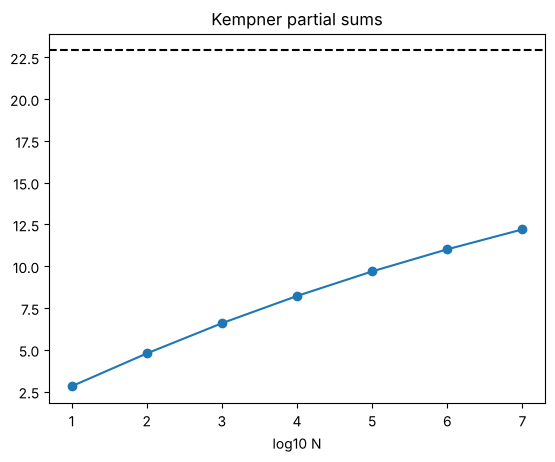

ratios of successive increments: [0.921, 0.902, 0.9, 0.9, 0.9]


In [11]:
def no_nine(n):
    return "9" not in str(n)

checkpoints, s, out = {10**k for k in range(1, 8)}, 0.0, []
for n in range(1, 10**7 + 1):
    if no_nine(n):
        s += 1 / n
    if n in checkpoints:
        out.append((n, s))
for n, v in out:
    print(f"N = 10^{int(math.log10(n))}: partial sum = {v:.4f}")
plt.plot([math.log10(n) for n, _ in out], [v for _, v in out], "o-"); plt.axhline(22.9207, ls="--", c="k")
plt.xlabel("log10 N"); plt.title("Kempner partial sums"); plt.show()
incs = [b[1] - a[1] for a, b in zip(out, out[1:])]
print("ratios of successive increments:", [round(b / a, 3) for a, b in zip(incs, incs[1:])])

Decade $k$ contributes about $8\cdot 9^{k-1}$ terms of size about $10^{-k}$, so the increments shrink by a factor close to $0.9$ per decade. After $10^7$ the remaining tail is about $10.7$, and $10.7 \times 0.9^m < 0.01$ needs $m \approx 66$ more decades: brute force would have to reach numbers with over 70 digits. Clever algorithms (Baillie, 1979) compute the sum to many digits in a fraction of a second.

## Guided workshop: exact checks and certified errors
These checks exercise the new book examples. Finite calculations test the implementation; the text supplies the general proofs.

In [ ]:
import sympy as sp
m=6
L=2*sum(sp.Rational(1,(2*k+1)*3**(2*k+1)) for k in range(m))
bound=sp.Rational(9,4*(2*m+1)*3**(2*m+1))
assert bound < sp.Rational(1,10**6)
assert 0 < (sp.log(2)-L).evalf(50) < bound.evalf(50)
print('Six-term log(2) approximation:',L.evalf(12),'proved truncation bound:',bound)
